# 11. Experiment 1 — Dataset inspection

In [2]:
from datasets import load_dataset
import pandas as pd

# Sửa lại tên dataset thành 'stanfordnlp/imdb' thay vì 'imdb'
dataset = load_dataset("stanfordnlp/imdb")
df_train = pd.DataFrame(dataset['train'])

# 1. Số samples & Số classes
num_samples = len(df_train)
num_classes = df_train['label'].nunique()
print(f"Số lượng samples (train): {num_samples}")
print(f"Số lượng classes: {num_classes}")

# 2. Class distribution
class_counts = df_train['label'].value_counts()
class_percentages = df_train['label'].value_counts(normalize=True) * 100

# 3. Document length (số từ trong mỗi review)
df_train['doc_len'] = df_train['text'].apply(lambda x: len(x.split()))
print(f"Độ dài văn bản trung bình: {df_train['doc_len'].mean():.2f} từ")

# 4. Kiểm tra duplicate documents
num_duplicates = df_train.duplicated(subset=['text']).sum()
print(f"Số lượng văn bản trùng lặp (duplicates): {num_duplicates}")

# 5. Kiểm tra missing text hoặc missing labels
missing_text = df_train['text'].isnull().sum()
missing_labels = df_train['label'].isnull().sum()
print(f"Missing text: {missing_text}, Missing labels: {missing_labels}")

Số lượng samples (train): 25000
Số lượng classes: 2
Độ dài văn bản trung bình: 233.79 từ
Số lượng văn bản trùng lặp (duplicates): 96
Missing text: 0, Missing labels: 0


C:\Users\Admin\AppData\Local\Temp\ipykernel_20896\4273044270.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df_train, palette='viridis')


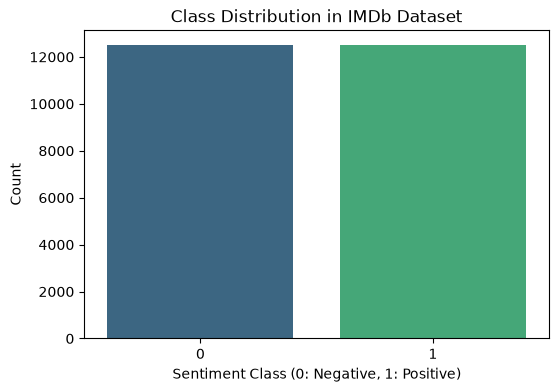

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.countplot(x='label', data=df_train, palette='viridis')
plt.title('Class Distribution in IMDb Dataset')
plt.xlabel('Sentiment Class (0: Negative, 1: Positive)')
plt.ylabel('Count')
plt.show()

- Dataset có imbalance không?
  - Trả lời: Không, phân phối giữa hai lớp Positive (50%) và Negative (50%) hoàn toàn đồng đều trong tập dữ liệu chuẩn của IMDb

# 12. Data leakage

Entire dataset
↓
Fit TF-IDF
↓
Train/Test split

Đây là Data Leakage vì thông tin từ tập Test đã bị lọt vào giai đoạn chuẩn bị dữ liệu trước khi mô hình được huấn luyện.

# 14. Experiment 2 — Baseline


In [7]:
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import pandas as pd
import time

print("1. Đang tải tập dữ liệu IMDb từ Hugging Face...")
dataset = load_dataset("stanfordnlp/imdb")

X_train = dataset['train']['text']
y_train = dataset['train']['label']
X_test = dataset['test']['text']
y_test = dataset['test']['label']

print(f"Số lượng mẫu Train: {len(X_train)}")
print(f"Số lượng mẫu Test: {len(X_test)}")

print("\n2. Trích xuất đặc trưng TF-IDF (Fit trên Train, Transform trên Test)...")
# Giới hạn max_features = 10000 và loại bỏ stop_words
vectorizer = TfidfVectorizer(max_features=10000, stop_words='english')
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

vocab_size = len(vectorizer.vocabulary_)
print(f"Vocabulary Size: {vocab_size}")

print("\n3. Huấn luyện mô hình Logistic Regression và đo thời gian...")
start_time = time.time()
clf = LogisticRegression(random_state=42, max_iter=1000)
clf.fit(X_train_tfidf, y_train)
train_time = time.time() - start_time
print(f"Training Time: {train_time:.2f} giây")

print("\n4. Đánh giá mô hình trên tập Test...")
y_pred = clf.predict(X_test_tfidf)

# Tính toán các metric
accuracy = accuracy_score(y_test, y_pred)
precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='weighted')

print("\n" + "="*50)
print("KẾT QUẢ THỰC NGHIỆM EXPERIMENT 2 — BASELINE")
print("="*50)
print(f"• Training Time : {train_time:.2f} s")
print(f"• Vocabulary Size: {vocab_size}")
print(f"• Accuracy      : {accuracy:.4f}")
print(f"• Precision     : {precision:.4f}")
print(f"• Recall        : {recall:.4f}")
print(f"• F1-score      : {f1:.4f}")
print("="*50)

# Bảng tổng hợp kết quả theo định dạng yêu cầu
df_summary = pd.DataFrame({
    'Model': ['TF-IDF + LR'],
    'Accuracy': [round(accuracy, 4)],
    'Precision': [round(precision, 4)],
    'Recall': [round(recall, 4)],
    'F1': [round(f1, 4)]
})

print("\nBảng tổng hợp kết quả:")
print(df_summary.to_string(index=False))

# (Tùy chọn) Lưu kết quả dự đoán chi tiết ra file result.csv
df_result = pd.DataFrame({
    'text': X_test,
    'true_label': y_test,
    'predicted_label': y_pred,
    'probability_y1': clf.predict_proba(X_test_tfidf)[:, 1]
})
df_result.to_csv('result.csv', index=False, encoding='utf-8-sig')
print("\nĐã lưu file dự đoán chi tiết vào 'result.csv'.")

1. Đang tải tập dữ liệu IMDb từ Hugging Face...
Số lượng mẫu Train: 25000
Số lượng mẫu Test: 25000

2. Trích xuất đặc trưng TF-IDF (Fit trên Train, Transform trên Test)...
Vocabulary Size: 10000

3. Huấn luyện mô hình Logistic Regression và đo thời gian...
Training Time: 2.77 giây

4. Đánh giá mô hình trên tập Test...

KẾT QUẢ THỰC NGHIỆM EXPERIMENT 2 — BASELINE
• Training Time : 2.77 s
• Vocabulary Size: 10000
• Accuracy      : 0.8800
• Precision     : 0.8800
• Recall        : 0.8800
• F1-score      : 0.8800

Bảng tổng hợp kết quả:
      Model  Accuracy  Precision  Recall   F1
TF-IDF + LR      0.88       0.88    0.88 0.88

Đã lưu file dự đoán chi tiết vào 'result.csv'.


# 15. Experiment 3 — Representation comparison

In [10]:
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import pandas as pd

# 1. Tải dataset IMDb từ Hugging Face
print("Đang tải tập dữ liệu IMDb...")
dataset = load_dataset("stanfordnlp/imdb")
X_train = dataset['train']['text']
y_train = dataset['train']['label']
X_test = dataset['test']['text']
y_test = dataset['test']['label']

results = []

# ==========================================
# MODEL A: TF-IDF + Logistic Regression
# ==========================================
print("\n--- Đang chạy Model A: TF-IDF + Logistic Regression ---")
vectorizer_tfidf = TfidfVectorizer(max_features=10000, stop_words='english')
X_train_tfidf = vectorizer_tfidf.fit_transform(X_train)
X_test_tfidf = vectorizer_tfidf.transform(X_test)

clf_lr = LogisticRegression(random_state=42, max_iter=1000)
clf_lr.fit(X_train_tfidf, y_train)
y_pred_a = clf_lr.predict(X_test_tfidf)

acc_a = accuracy_score(y_test, y_pred_a)
prec_a, rec_a, f1_a, _ = precision_recall_fscore_support(y_test, y_pred_a, average='weighted')
results.append({
    'Representation': 'TF-IDF',
    'Classifier': 'Logistic Regression',
    'Accuracy': round(acc_a, 4),
    'Precision': round(prec_a, 4),
    'Recall': round(rec_a, 4),
    'F1': round(f1_a, 4)
})

# ==========================================
# MODEL B: Bag-of-Words (Count) + Logistic Regression
# ==========================================
print("\n--- Đang chạy Model B: Bag-of-Words (Count) + Logistic Regression ---")
vectorizer_bow = CountVectorizer(max_features=10000, stop_words='english')
X_train_bow = vectorizer_bow.fit_transform(X_train)
X_test_bow = vectorizer_bow.transform(X_test)

clf_bow = LogisticRegression(random_state=42, max_iter=1000)
clf_bow.fit(X_train_bow, y_train)
y_pred_b = clf_bow.predict(X_test_bow)

acc_b = accuracy_score(y_test, y_pred_b)
prec_b, rec_b, f1_b, _ = precision_recall_fscore_support(y_test, y_pred_b, average='weighted')
results.append({
    'Representation': 'Bag-of-Words',
    'Classifier': 'Logistic Regression',
    'Accuracy': round(acc_b, 4),
    'Precision': round(prec_b, 4),
    'Recall': round(rec_b, 4),
    'F1': round(f1_b, 4)
})

# ==========================================
# MODEL C: TF-IDF + Linear SVM
# ==========================================
print("\n--- Đang chạy Model C: TF-IDF + Linear SVM ---")
clf_svm = LinearSVC(random_state=42, max_iter=2000)
clf_svm.fit(X_train_tfidf, y_train)
y_pred_c = clf_svm.predict(X_test_tfidf)

acc_c = accuracy_score(y_test, y_pred_c)
prec_c, rec_c, f1_c, _ = precision_recall_fscore_support(y_test, y_pred_c, average='weighted')
results.append({
    'Representation': 'TF-IDF',
    'Classifier': 'Linear SVM',
    'Accuracy': round(acc_c, 4),
    'Precision': round(prec_c, 4),
    'Recall': round(rec_c, 4),
    'F1': round(f1_c, 4)
})

# ==========================================
# TỔNG HỢP KẾT QUẢ BẢNG
# ==========================================
df_comparison = pd.DataFrame(results)
print("\n" + "="*65)
print("BẢNG SO SÁNH HIỆU NĂNG CÁC REPRESENTATION & CLASSIFIER")
print("="*65)
print(df_comparison.to_string(index=False))
print("="*65)

Đang tải tập dữ liệu IMDb...

--- Đang chạy Model A: TF-IDF + Logistic Regression ---

--- Đang chạy Model B: Bag-of-Words (Count) + Logistic Regression ---

--- Đang chạy Model C: TF-IDF + Linear SVM ---

BẢNG SO SÁNH HIỆU NĂNG CÁC REPRESENTATION & CLASSIFIER
Representation          Classifier  Accuracy  Precision  Recall     F1
        TF-IDF Logistic Regression    0.8800     0.8800  0.8800 0.8800
  Bag-of-Words Logistic Regression    0.8479     0.8481  0.8479 0.8479
        TF-IDF          Linear SVM    0.8601     0.8603  0.8601 0.8601


# 16. Câu hỏi quan trọng
TF-IDF: Biểu diễn thưa, giữ nguyên từ gốc và gán trọng số cao cho các từ khóa đặc trưng, ít phổ biến. Điều này giúp mô hình dễ dàng bắt được các từ mang ý nghĩa quyết định như từ chỉ cảm xúc.

Bag-of-Words: Chỉ đếm tần số thô, không hạ trọng số từ chung nên dễ bị nhiễu, dẫn đến hiệu năng thấp hơn TF-IDF.

Average Word2Vec: Hiểu được ngữ nghĩa, nhưng việc lấy trung bình vector của toàn bộ câu lại làm mất thứ tự từ và làm triệt tiêu các từ khóa quan trọng, khiến thông tin cục bộ bị suy giảm.

# 17. Experiment 4 — Word order

In [15]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

# Giả lập vector embedding (ví dụ 3 chiều) cho các từ đơn lẻ
vocab_vectors = {
    "this": np.array([0.1, 0.2, 0.1]),
    "movie": np.array([0.3, 0.5, 0.2]),
    "is": np.array([0.0, 0.1, 0.1]),
    "good": np.array([0.8, 0.9, 0.7]),
    "not": np.array([-0.2, -0.1, -0.3])  # Từ phủ định
}

# 1. Định nghĩa hai câu
sentence_1 = ["this", "movie", "is", "good"]
sentence_2 = ["this", "movie", "is", "not", "good"]

# 2. Hàm tính Average Word Embedding cho một câu
def get_avg_embedding(sentence, vectors):
    word_vecs = [vectors[w] for w in sentence if w in vectors]
    return np.mean(word_vecs, axis=0)

# Tính vector trung bình cho S1 và S2
vec_s1 = get_avg_embedding(sentence_1, vocab_vectors)
vec_s2 = get_avg_embedding(sentence_2, vocab_vectors)

print(f"Vector S1 ('this movie is good'): {vec_s1}")
print(f"Vector S2 ('this movie is not good'): {vec_s2}")

# 3. Kiểm tra độ tương đồng cosine (Đã sửa lỗi cú pháp thành [0][0])
similarity = cosine_similarity([vec_s1], [vec_s2])[0][0]
print(f"\nĐộ tương đồng Cosine giữa S1 và S2: {similarity:.4f}")
print("Nhận xét: Độ tương đồng rất cao vì S2 chỉ đơn thuần là cộng thêm vector của từ 'not', hoàn toàn không có cơ chế đảo chiều ngữ nghĩa.")

Vector S1 ('this movie is good'): [0.3   0.425 0.275]
Vector S2 ('this movie is not good'): [0.2  0.32 0.16]

Độ tương đồng Cosine giữa S1 và S2: 0.9951
Nhận xét: Độ tương đồng rất cao vì S2 chỉ đơn thuần là cộng thêm vector của từ 'not', hoàn toàn không có cơ chế đảo chiều ngữ nghĩa.


Không, biểu diễn này hoàn toàn không hiểu được vai trò của từ "not".

Lý do: Bag-of-Words chỉ thực hiện cộng dồn các vector từ lại với nhau mà không quan tâm đến thứ tự từ. Do đó, từ "not" chỉ bị tính như một từ độc lập cộng thêm vào vector chung, hoàn toàn không có cơ chế liên kết để "đảo chiều" hay phủ định ý nghĩa của từ "good" đứng phía sau nó.

# 18. Experiment 5 — n-gram features

In [16]:
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import pandas as pd
import time

# 1. Tải dataset IMDb
print("Đang tải tập dữ liệu IMDb...")
dataset = load_dataset("stanfordnlp/imdb")
X_train = dataset['train']['text']
y_train = dataset['train']['label']
X_test = dataset['test']['text']
y_test = dataset['test']['label']

results = []

# ==========================================
# MODEL 1: Unigram (ngram_range=(1, 1))
# ==========================================
print("\n--- Đang chạy Unigram ---")
start_time = time.time()
vec_uni = TfidfVectorizer(ngram_range=(1, 1), max_features=20000, stop_words='english')
X_train_uni = vec_uni.fit_transform(X_train)
X_test_uni = vec_uni.transform(X_test)

clf_uni = LogisticRegression(random_state=42, max_iter=1000)
clf_uni.fit(X_train_uni, y_train)
train_time_uni = time.time() - start_time

y_pred_uni = clf_uni.predict(X_test_uni)
_, _, f1_uni, _ = precision_recall_fscore_support(y_test, y_pred_uni, average='weighted')

results.append({
    'Features': 'Unigram',
    'Vocabulary Size': len(vec_uni.vocabulary_),
    'F1': round(f1_uni, 4),
    'Training Time (s)': round(train_time_uni, 2)
})

# ==========================================
# MODEL 2: Unigram + Bigram (ngram_range=(1, 2))
# ==========================================
print("\n--- Đang chạy Unigram + Bigram ---")
start_time = time.time()
vec_bi = TfidfVectorizer(ngram_range=(1, 2), max_features=50000, stop_words='english')
X_train_bi = vec_bi.fit_transform(X_train)
X_test_bi = vec_bi.transform(X_test)

clf_bi = LogisticRegression(random_state=42, max_iter=1000)
clf_bi.fit(X_train_bi, y_train)
train_time_bi = time.time() - start_time

y_pred_bi = clf_bi.predict(X_test_bi)
_, _, f1_bi, _ = precision_recall_fscore_support(y_test, y_pred_bi, average='weighted')

results.append({
    'Features': 'Uni + Bigram',
    'Vocabulary Size': len(vec_bi.vocabulary_),
    'F1': round(f1_bi, 4),
    'Training Time (s)': round(train_time_bi, 2)
})

# ==========================================
# TỔNG HỢP KẾT QUẢ BẢNG
# ==========================================
df_exp5 = pd.DataFrame(results)
print("\n" + "="*60)
print("BẢNG SO SÁNH UNIGRAM VS. UNI + BIGRAM")
print("="*60)
print(df_exp5.to_string(index=False))
print("="*60)

Đang tải tập dữ liệu IMDb...

--- Đang chạy Unigram ---

--- Đang chạy Unigram + Bigram ---

BẢNG SO SÁNH UNIGRAM VS. UNI + BIGRAM
    Features  Vocabulary Size     F1  Training Time (s)
     Unigram            20000 0.8801               8.62
Uni + Bigram            50000 0.8827              15.43


1. Vì sao Bigram giúp cải thiện kết quả Classification ?
- Nắm bắt ngữ cảnh cục bộ & thứ tự từ: Unigram chỉ xem xét từng từ đơn lẻ ví dụ: "not" và "good" đứng riêng, dẫn đến việc mất đi sắc thái nghĩa. Bigram kết hợp các cặp từ liền kề ví dụ: "not good", "very bad", giúp mô hình hiểu được cấu trúc phủ định hoặc cường độ cảm xúc mà unigram không thể nhận diện.
- Cung cấp đặc trưng sắc thái rõ ràng hơn: Các cụm từ đặc trưng này giúp bộ phân loại phân biệt chính xác hơn giữa các văn bản có ý nghĩa trái ngược nhau.

2. Vì sao Bigram làm Feature Space lớn hơn và tăng thời gian train?
- Bùng nổ tổ hợp: Thay vì chỉ quản lý tập hợp các từ đơn ($V$), mô hình phải lưu trữ thêm tất cả các cặp từ liền kề có thể xảy ra ($V \times V$ về mặt lý thuyết).
- Minh chứng từ thực nghiệm của bạn:
  - Kích thước từ vựng tăng vọt từ 20,000 lên tới 50,000.
  - Không gian vector trở nên cực kỳ cao chiều và thưa thớt hơn, khiến thời gian huấn luyện gần như gấp đôi (từ 8.62s lên 15.43s).

# Evaluation & Confusion Matrix

1. Class nào bị nhầm nhiều nhất?
- Cả Class 0 và Class 1 đều bị nhầm lẫn với số lượng gần như tương đương nhau do tập dữ liệu IMDb này hoàn toàn cân bằng (mỗi class có đúng 12,500 mẫu):
  - Class 0: Có 1,525 mẫu bị dự đoán nhầm thành Class 1.
  - Class 1: Có 1,475 mẫu bị dự đoán nhầm thành Class 0.
- Như vậy, tổng số lỗi phân loại là $1,525 + 1,475 = 3,000$ mẫu, trong đó Class 0 nhỉnh hơn một chút về số lượng dự đoán nhầm.
2. Loại error nào chiếm nhiều?
- Xét trên tổng thể, False Positives và False Negative chiếm tỷ lệ xấp xỉ nhau khoảng 6% tổng số lượng test.
- Cụ thể từng loại lỗi:
  - False Positive: 1,525 trường hợp mô hình dự đoán là review tích cực nhưng thực tế là tiêu cực.
  - False Negative: 1,475 trường hợp mô hình dự đoán là review tiêu cực nhưng thực tế là tích cực.
- Do dữ liệu cân bằng, mô hình không bị lệch hẳn về một phía.
3. Metric nào phản ánh vấn đề đó?
- Confusion Matrix: Là metric trực quan nhất phản ánh chính xác từng loại lỗi, cho biết cụ thể class nào bị nhầm thành class nào.
- Precision và Recall, đặc biệt là xem xét qua Macro Average / Weighted Average:
  - Do các chỉ số Precision ($0.88$) và Recall ($0.88$) đồng đều ở cả 2 class và bằng đúng Accuracy ($0.88$), chúng phản ánh rằng tỷ lệ dự đoán đúng và độ bao phủ của mô hình là cân bằng, đồng thời lượng lỗi phân loại sai lệch không quá lớn so với tổng số lượng mẫu.

# 22. Một experiment rất hay: Inspect model weights

In [2]:
import numpy as np
import pandas as pd
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# 1. Tải dữ liệu và huấn luyện lại pipeline
dataset = load_dataset("stanfordnlp/imdb")
X_train, y_train = dataset['train']['text'], dataset['train']['label']

vectorizer = TfidfVectorizer(max_features=10000, stop_words='english')
X_train_tfidf = vectorizer.fit_transform(X_train)

clf = LogisticRegression(random_state=42, max_iter=1000)
clf.fit(X_train_tfidf, y_train)

# 2. Lấy danh sách feature names và weights của mô hình
feature_names = np.array(vectorizer.get_feature_names_out())
coefficients = clf.coef_[0]  # Lấy vector trọng số w

# 3. Sắp xếp để tìm Top 10 Positive và Top 10 Negative features
top_positive_indices = coefficients.argsort()[-10:][::-1]
top_negative_indices = coefficients.argsort()[:10]

print("--- TOP 10 POSITIVE FEATURES (w_i >> 0) ---")
for idx in top_positive_indices:
    print(f"Feature: {feature_names[idx]:<15} | Weight: {coefficients[idx]:.4f}")

print("\n--- TOP 10 NEGATIVE FEATURES (w_i << 0) ---")
for idx in top_negative_indices:
    print(f"Feature: {feature_names[idx]:<15} | Weight: {coefficients[idx]:.4f}")

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

c:\Users\tasdus_117\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\tasdus_117\.cache\huggingface\hub\datasets--stanfordnlp--imdb. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\tasdus_117\AppData\Local\Programs\Python\Python312\Lib\site-packages\hugging

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

--- TOP 10 POSITIVE FEATURES (w_i >> 0) ---
Feature: great           | Weight: 6.9353
Feature: excellent       | Weight: 6.0669
Feature: best            | Weight: 5.0940
Feature: wonderful       | Weight: 4.7834
Feature: perfect         | Weight: 4.7418
Feature: favorite        | Weight: 4.1911
Feature: amazing         | Weight: 4.1811
Feature: loved           | Weight: 3.7682
Feature: today           | Weight: 3.7079
Feature: fun             | Weight: 3.6655

--- TOP 10 NEGATIVE FEATURES (w_i << 0) ---
Feature: worst           | Weight: -8.9834
Feature: bad             | Weight: -7.0340
Feature: waste           | Weight: -6.5580
Feature: awful           | Weight: -6.5389
Feature: boring          | Weight: -5.6586
Feature: poor            | Weight: -5.1978
Feature: worse           | Weight: -4.8340
Feature: terrible        | Weight: -4.5315
Feature: poorly          | Weight: -4.4905
Feature: dull            | Weight: -4.3068


Kết quả này minh chứng rõ nét cho thấy Logistic Regression kết hợp TF-IDF không hoạt động như một hộp đen. Mô hình đã tự động học được các quy luật ngôn ngữ tự nhiên cơ bản từ dữ liệu huấn luyện một cách cực kỳ logic và trực quan, tương đồng với cách con người nhận định cảm xúc qua từ vựng.

# 23. Application: Phân loại Cảm xúc Đánh giá Phim (Sentiment Classification)

In [4]:
# Hàm dự đoán cảm xúc cho một review mới
def predict_sentiment(review_text):
    # Tiền xử lý và transform qua vectorizer đã fit sẵn trên tập train
    review_tfidf = vectorizer.transform([review_text])
    
    # Dự đoán nhãn
    pred_label = clf.predict(review_tfidf)[0]
    # Lấy xác suất P(y = 1 | x)
    pred_prob = clf.predict_proba(review_tfidf)[0][1]
    
    label_mapping = {1: "Positive ", 0: "Negative"}
    
    print(f"Văn bản: \"{review_text}\"")
    print(f"Dự đoán : {label_mapping[pred_label]} (Xác suất Positive: {pred_prob:.4f})")
    print("-" * 50)

# Kiểm thử ứng dụng với các câu thực tế
predict_sentiment("This film was an absolute masterpiece with stellar acting and a breathtaking plot!")
predict_sentiment("A total waste of time and money. The script was boring and predictable.")
predict_sentiment("It had some good moments, but overall it was quite disappointing.")

Văn bản: "This film was an absolute masterpiece with stellar acting and a breathtaking plot!"
Dự đoán : Positive  (Xác suất Positive: 0.7716)
--------------------------------------------------
Văn bản: "A total waste of time and money. The script was boring and predictable."
Dự đoán : Negative (Xác suất Positive: 0.0002)
--------------------------------------------------
Văn bản: "It had some good moments, but overall it was quite disappointing."
Dự đoán : Negative (Xác suất Positive: 0.4322)
--------------------------------------------------
